# 04 — Analysis and Scoring

**Objective:** Score all 30 vehicle-part combinations using a weighted priority formula, run a sensitivity analysis, and recommend the top 5 parts for import.

**Assignment requirements:**
- *"Create and justify your own scoring formula."*
- *"How each factor becomes a number"*
- *"Why each weight was chosen"*
- *"Whether changing the weights changes the ranking"*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned data
cleaned = pd.read_csv('../data/cleaned/cleaned_observations.csv')
print(f"Cleaned observations loaded: {len(cleaned)} rows")
cleaned.head()

Cleaned observations loaded: 59 rows


,observation_id,vehicle,model_year,part_category,part_description,oem_part_number,supplier,price,currency,availability,...,source_id,source_url,collection_date,evidence_type,notes,observation_type,price_usd,price_missing,is_cross_checked,compatibility_strength
0,OBS001,BYD Seagull,2023-2024,Bumper,Front Bumper,EQEA-2083111,Landin BYD Parts,198.0,RMB,in_stock,...,S003,https://www.landinparts.com/p.html#/byd/byd002...,2026-11-18,supplier_catalogue,SKU: BYD0020040; Landin catalog extraction,supplier_catalogue,27.72,False,False,catalogue_match
1,OBS002,BYD Seagull,2023-2024,Bumper,Front Bumper,EQEE-2803111,Landin BYD Parts,165.0,RMB,in_stock,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040040U1; Landin catalog extraction,supplier_catalogue,23.10,False,False,catalogue_match
2,OBS003,BYD Seagull,2023-2024,Bumper,Front Bumper,EQEA-2803112,Landin BYD Parts,88.0,RMB,in_stock,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040040L6; Landin catalog extraction,supplier_catalogue,12.32,False,False,catalogue_match
3,OBS004,BYD Seagull,2023-2024,Bumper,Rear Bumper,EQEA-2804110A/00,Landin BYD Parts,NaN,NaN,price_on_request,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040190; Landin catalog extraction,supplier_catalogue,NaN,True,False,catalogue_match
4,OBS005,BYD Seagull,2023-2024,Fender / body panel,Front Door Panel,EQEA-6101019/70,Landin BYD Parts,NaN,NaN,price_on_request,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040232; Landin catalog extraction,supplier_catalogue,NaN,True,False,catalogue_match


## 4.1 Scoring Model Design

### Five Scoring Factors

| Factor | Weight | What It Measures | Justification for Weight |
|--------|:------:|------------------|-------------------------|
| **Demand Evidence ($D$)** | **30%** | Observed vehicle marketplace presence on Adey Market (S001) + component functional wear classification (friction wear vs collision repair vs structural). | Highest weight because an importer's greatest commercial risk is stocking parts with low market turnover. *(Note: NHTSA defect records are documented separately as engineering platform context and are explicitly decoupled from demand scoring).* |
| **Observed Public Catalogue Scarcity ($S$)** | **25%** | Degree to which a part is absent from the public catalogues investigated (Gezat S002, Landin S003, toyota-spare-parts S005). | Second-highest weight because public supply gaps indicate immediate commercial stocking necessity. *(Note: Measures online catalogue scarcity only; does not establish physical unavailability in Addis Ababa shops).* |
| **Vehicle Compatibility ($C$)** | **20%** | Verification level of supplier-listed OE reference in named catalogues. | Wrong-fit part shipments cause costly cross-border returns and dead inventory. Verified supplier OE references mitigate this risk. |
| **Catalogue Sourcing Practicality ($P$)** | **15%** | Active listing status and unit catalogue price brackets in verified catalogues. | Evaluates whether a part can be procured with transparent catalogue pricing. Unverified trade quotations receive P=1 because sourcing feasibility cannot be confirmed without an active, verified supplier listing. |
| **Evidence Confidence ($E$)** | **10%** | Degree of cross-validation across independent sources (S001–S008). | Acts as a data-quality trust multiplier, validating the reliability of underlying catalogue sources. |

**Weights Total:** 0.30 + 0.25 + 0.20 + 0.15 + 0.10 = **1.00 (100%)**


### Rating Scale (1–5) Grounded in Collected Evidence

#### Demand Evidence ($D$ — 30%)
*Grounded in: Observed vehicle marketplace presence on Adey Market (S001) and component functional wear classification.*
| Score | Empirical Criteria |
|:-----:|-------------------|
| **5** | Dominant vehicle market presence on Adey Market (e.g. BYD Seagull / Yuan Up) + primary friction wear or high-exposure exterior contact item (analyst assessment). |
| **4** | High vehicle market presence on Adey Market + secondary wear or collision-repair component. |
| **3** | Moderate vehicle presence on Adey Market + slower-wearing mechanical component (e.g. brake discs with EV regenerative braking assist) or secondary body panel. |
| **2** | Lower vehicle presence or rarely replaced structural part. |
| **1** | Minimal marketplace presence or negligible replacement indication. |
*(Note: Analyst judgement applying vehicle listing density and mechanical component type. No on-the-ground workshop replacement rates were measured).*

#### Observed Public Catalogue Scarcity ($S$ — 25%)
*Grounded in: The degree to which a part is absent from the public catalogues investigated (S002 Gezat local distributor, S003 Landin overseas supplier, S005 third-party catalogue).*
| Score | Empirical Criteria |
|:-----:|-------------------|
| **5** | Confirmed catalogue gap across searched supplier portals (e.g. BYD Yuan Up on Landin S003). |
| **4** | Dedicated EV model-specific component; absent from investigated local distributor catalogue (Gezat S002); available via overseas supplier catalogue (Landin S003 / toyota-spare-parts S005). |
| **3** | Available in overseas catalogue with standard cross-border order lead times. |
| **2** | Broad multi-model cross-compatibility documented across common platforms (e.g. TNGA platform), reducing catalogue scarcity. |
| **1** | Readily listed in investigated local distributor catalogue (Gezat S002). |
*(Note: Measures investigated public catalogue scarcity only; does not establish physical unavailability in Addis Ababa shops).*

#### Vehicle Compatibility ($C$ — 20%)
*Grounded in: Verification level of part number in named source catalogues.*
| Score | Empirical Criteria |
|:-----:|-------------------|
| **5** | Supplier-listed OE reference confirmed in named supplier catalogue (Landin S003) with an explicit vehicle model compatibility statement. |
| **4** | Part number listed in third-party parts catalogue (toyota-spare-parts.com S005) with chassis diagram (XEAM10), pending independent dealer EPC confirmation. |
| **3** | Secondary commercial cross-reference without direct catalogue listing. |
| **2** | Trade listing code from unverified export directory (S008); format not confirmed by OEM EPC. |
| **1** | Catalogue gap — no part number or fitment evidence found in investigated sources. |

#### Catalogue Sourcing Practicality ($P$ — 15%)
*Grounded in: Active listing status and unit price visibility in verified catalogues (does not assume freight quotes, landed costs, or profit margins).*
| Score | Empirical Criteria |
|:-----:|-------------------|
| **5** | Active catalogue listing with transparent unit price under $50 USD (low unit capital exposure). |
| **4** | Active catalogue listing with transparent unit price between $50 and $250 USD. |
| **3** | Active catalogue listing with unit price over $250 USD, or listed as "Price on request" (unpriced body panels). |
| **2** | Catalogue listing exists but supplier ordering mechanism is inactive. |
| **1** | Unverified trade quotation (S008) or catalogue gap (no verified supplier, no verifiable price). |

#### Evidence Confidence ($E$ — 10%)
*Grounded in: Primary source verification and independent cross-checking.*
| Score | Empirical Criteria |
|:-----:|-------------------|
| **5** | Named supplier catalogue listing (Landin S003) corroborated with secondary reference benchmark (CQSW S004). |
| **4** | Named supplier catalogue listing with supplier-listed OE reference (single named source). |
| **3** | Third-party aggregator catalogue listing (toyota-spare-parts.com S005). |
| **2** | Single commercial aftermarket reference. |
| **1** | Unverified trade quotation (S008) or catalogue gap record. |


In [2]:
# Define the scoring weights
WEIGHTS = {
    'demand_evidence': 0.30,
    'market_scarcity': 0.25,
    'vehicle_compatibility': 0.20,
    'sourcing_practicality': 0.15,
    'evidence_confidence': 0.10
}

print("Scoring weights:")
for factor, weight in WEIGHTS.items():
    print(f"  {factor}: {weight:.0%}")
print(f"  Total: {sum(WEIGHTS.values()):.0%}")

Scoring weights:
  demand_evidence: 30%
  market_scarcity: 25%
  vehicle_compatibility: 20%
  sourcing_practicality: 15%
  evidence_confidence: 10%
  Total: 100%


## 4.2 Assigned Scores & Empirical Justifications

Each of the 30 vehicle-part combinations is evaluated across the 5 factors using the evidence-grounded rubric defined above.

The scoring matrix is imported from `scrapper/generate_scores_defensible.py`. Every assigned score is accompanied by an empirical evidence justification citing specific observation records from `data/raw/raw_observations.csv`.

**Unit of Analysis**: The scoring model evaluates 30 distinct **Vehicle Model + Part Category** combinations. The top recommendations represent prioritized categories accompanied by specific supplier-listed OE applications for commercial implementation.


In [3]:
# Load the complete, evidence-justified scoring table covering all 30 vehicle-part combinations
import sys
sys.path.insert(0, '..')

from scrapper.generate_scores_defensible import get_scoring_data, calculate_scores, run_sensitivity_analysis, WEIGHTS as SCENARIO_WEIGHTS
scores_data = get_scoring_data()

scores_df = pd.DataFrame(scores_data)
print(f'Scoring table loaded: {len(scores_df)} combinations across 3 vehicles and 10 categories.')
scores_df.head(10)


Scoring table loaded: 30 combinations across 3 vehicles and 10 categories.


,vehicle,part_category,demand_evidence,market_scarcity,vehicle_compatibility,sourcing_practicality,evidence_confidence,score_justification
0,BYD Seagull,Side mirror,5,4,5,5,5,D=5: High Adey Market presence (25+ listings) ...
1,BYD Seagull,Brake pads,4,4,5,5,5,D=4: High Adey presence + routine friction wea...
2,BYD Seagull,Shock absorber,4,4,5,4,5,D=4: High Adey presence + suspension damping w...
3,BYD Seagull,Headlight assembly,4,4,5,4,5,D=4: High Adey presence + frontal impact colli...
4,BYD Seagull,Bumper,4,4,5,3,5,D=4: High Adey presence + common collision rep...
5,BYD Seagull,Brake discs,3,4,5,4,5,D=3: Slower wear cycle than pads due to EV reg...
6,BYD Seagull,Tail-light assembly,3,4,5,4,5,D=3: Rear impact replacement item; lower turno...
7,BYD Seagull,Fender / body panel,3,4,5,3,5,D=3: Collision-only sheet metal panels; slower...
8,BYD Seagull,Cabin-air filter,4,5,1,1,1,D=4: Routine maintenance consumable item. S=5:...
9,BYD Seagull,Wiper blades,4,3,1,1,1,D=4: Periodic maintenance consumable. S=3: OEM...


## 4.3 Calculate Priority Scores

In [4]:
# Calculate scores using the authoritative defensible scoring engine
# Formula: Score = (0.30 * D) + (0.25 * S) + (0.20 * C) + (0.15 * P) + (0.10 * E)
# Where each factor is rated 1-5 and weights sum to 1.0
scores_df = calculate_scores(scores_df)

print('=== Priority Ranking ===')
print(scores_df[['rank', 'vehicle', 'part_category', 'priority_score']].to_string(index=False))


=== Priority Ranking ===
 rank     vehicle       part_category  priority_score
    1 BYD Seagull         Side mirror            4.75
    2 BYD Seagull          Brake pads            4.45
    3 BYD Seagull      Shock absorber            4.30
    4 BYD Seagull  Headlight assembly            4.30
    5 BYD Seagull              Bumper            4.15
    6 BYD Seagull         Brake discs            4.00
    7 BYD Seagull Tail-light assembly            4.00
    8 Toyota bZ4X      Shock absorber            3.90
    9 BYD Seagull Fender / body panel            3.85
   10 Toyota bZ4X         Side mirror            3.75
   11 Toyota bZ4X              Bumper            3.75
   12 Toyota bZ4X  Headlight assembly            3.70
   13 Toyota bZ4X          Brake pads            3.65
   14 Toyota bZ4X    Cabin-air filter            3.55
   15 Toyota bZ4X        Wiper blades            3.55
   16 Toyota bZ4X Tail-light assembly            3.45
   17 Toyota bZ4X Fender / body panel            3.45
   

## 4.4 Sensitivity Analysis

**Question:** If we change the weights, does the top-5 ranking change?

We test three alternative weight scenarios to check whether the recommendation is robust or fragile.

In [5]:
# Execute sensitivity analysis using the authoritative defensible engine
# Compares baseline against Scarcity-first, Equal weights, and Evidence-focused scenarios
sens_df, stability_summary = run_sensitivity_analysis(scores_df)

# Display sensitivity rankings
sens_df


,Original,Scarcity-first,Equal weights,Evidence-focused
Rank 1,BYD Seagull — Side mirror,BYD Seagull — Side mirror,BYD Seagull — Side mirror,BYD Seagull — Side mirror
Rank 2,BYD Seagull — Brake pads,BYD Seagull — Brake pads,BYD Seagull — Brake pads,BYD Seagull — Brake pads
Rank 3,BYD Seagull — Shock absorber,BYD Seagull — Shock absorber,BYD Seagull — Shock absorber,BYD Seagull — Shock absorber
Rank 4,BYD Seagull — Headlight assembly,BYD Seagull — Headlight assembly,BYD Seagull — Headlight assembly,BYD Seagull — Headlight assembly
Rank 5,BYD Seagull — Bumper,BYD Seagull — Bumper,BYD Seagull — Bumper,BYD Seagull — Bumper


In [6]:
# Check stability: how many of the original top 5 remain in each alternative scenario?
baseline_top5 = stability_summary['Original']['top5']

print('=== Ranking Stability Analysis ===')
print(f'Baseline Top 5: {baseline_top5}\n')

for scenario_name, info in stability_summary.items():
    print(f"Scenario: {scenario_name:<20} | Top 5 Overlap: {info['overlap']}/5 | Stability: {info['stability_pct']:.0f}%")


=== Ranking Stability Analysis ===
Baseline Top 5: ['BYD Seagull — Side mirror', 'BYD Seagull — Brake pads', 'BYD Seagull — Shock absorber', 'BYD Seagull — Headlight assembly', 'BYD Seagull — Bumper']

Scenario: Original             | Top 5 Overlap: 5/5 | Stability: 100%
Scenario: Scarcity-first       | Top 5 Overlap: 5/5 | Stability: 100%
Scenario: Equal weights        | Top 5 Overlap: 5/5 | Stability: 100%
Scenario: Evidence-focused     | Top 5 Overlap: 5/5 | Stability: 100%


## 4.5 Visualizations

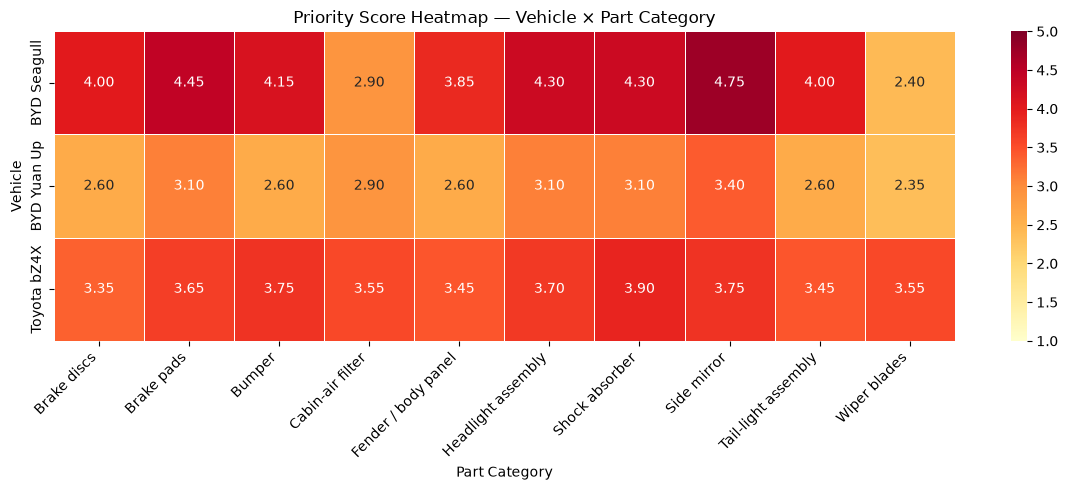

In [7]:
# Heatmap of scores by vehicle and part category
fig, ax = plt.subplots(figsize=(12, 5))

pivot = scores_df.pivot_table(
    values='priority_score',
    index='vehicle',
    columns='part_category'
)

sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, vmin=1, vmax=5)
ax.set_title('Priority Score Heatmap — Vehicle × Part Category')
ax.set_xlabel('Part Category')
ax.set_ylabel('Vehicle')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

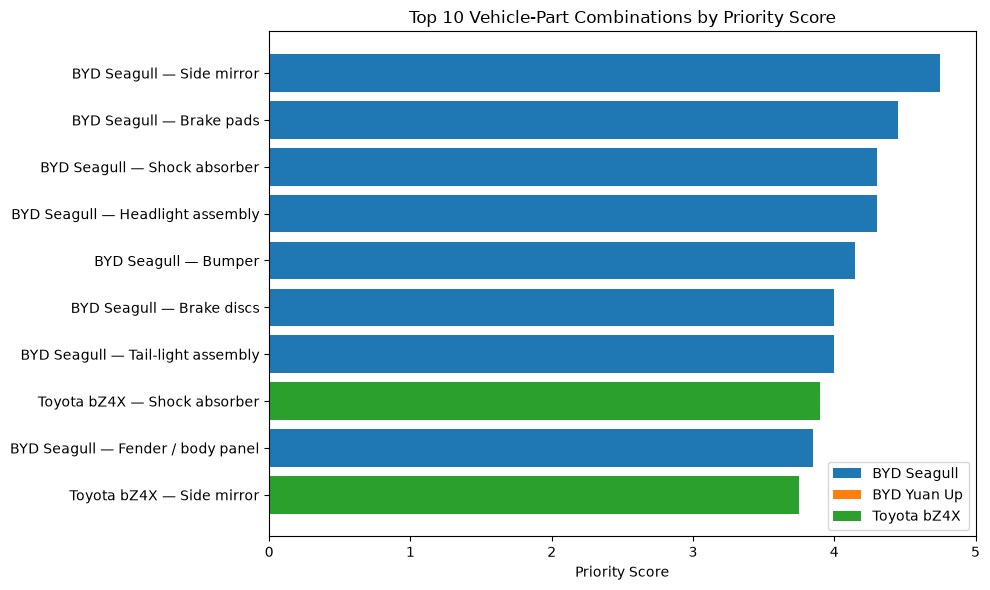

In [8]:
# Bar chart: Top 10 vehicle-part combinations
fig, ax = plt.subplots(figsize=(10, 6))

top10 = scores_df.nlargest(10, 'priority_score').copy()
top10['label'] = top10['vehicle'] + ' — ' + top10['part_category']

colors = {'BYD Seagull': '#1f77b4', 'BYD Yuan Up': '#ff7f0e', 'Toyota bZ4X': '#2ca02c'}
bar_colors = [colors.get(v, '#333333') for v in top10['vehicle']]

ax.barh(top10['label'][::-1], top10['priority_score'][::-1], color=bar_colors[::-1])
ax.set_xlabel('Priority Score')
ax.set_title('Top 10 Vehicle-Part Combinations by Priority Score')
ax.set_xlim(0, 5)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=v) for v, c in colors.items()]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

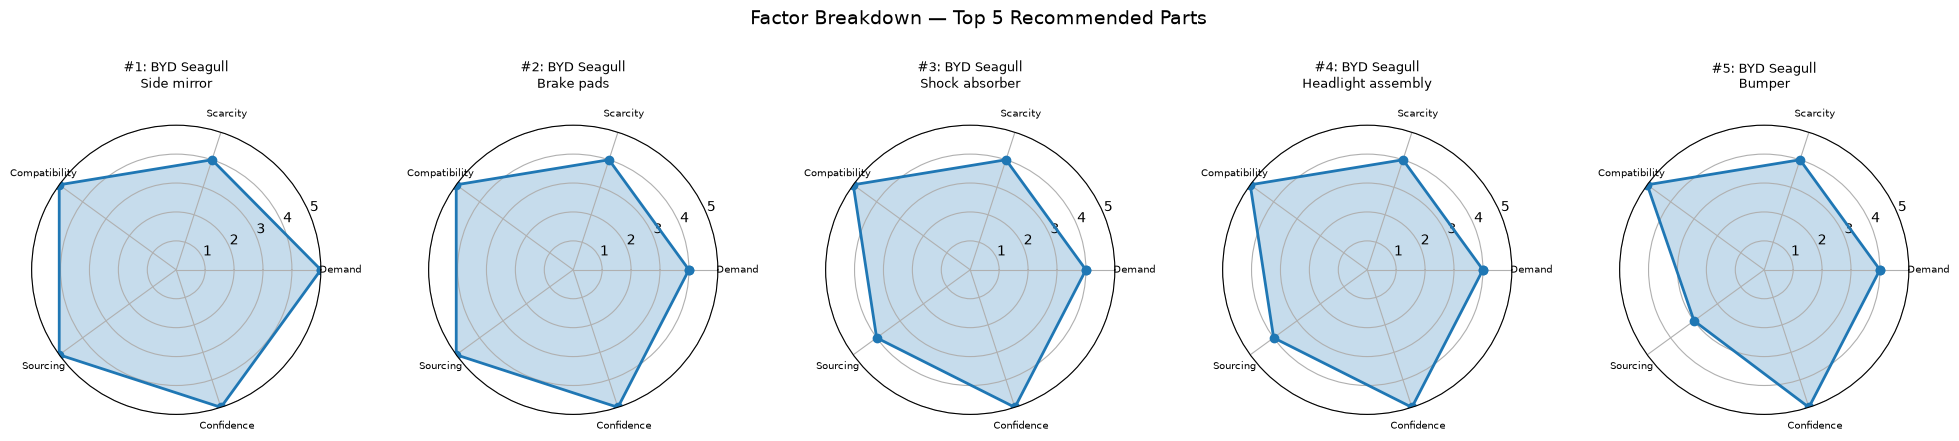

In [9]:
# Radar chart: Factor breakdown for the top 5 recommendations
from math import pi

top5_df = scores_df.nlargest(5, 'priority_score')
factors = ['demand_evidence', 'market_scarcity', 'vehicle_compatibility',
           'sourcing_practicality', 'evidence_confidence']
factor_labels = ['Demand', 'Scarcity', 'Compatibility', 'Sourcing', 'Confidence']

fig, axes = plt.subplots(1, 5, figsize=(20, 4), subplot_kw=dict(polar=True))

for idx, (_, row) in enumerate(top5_df.iterrows()):
    ax = axes[idx]
    values = [row[f] for f in factors]
    values += values[:1]  # Close the polygon
    
    angles = [n / float(len(factors)) * 2 * pi for n in range(len(factors))]
    angles += angles[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2)
    ax.fill(angles, values, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(factor_labels, size=7)
    ax.set_ylim(0, 5)
    ax.set_title(f"#{idx+1}: {row['vehicle']}\n{row['part_category']}", size=9, pad=15)

plt.suptitle('Factor Breakdown — Top 5 Recommended Parts', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

## 4.6 Final Recommendations

In [10]:
# Display the top 5 recommendations
top5_final = scores_df.nlargest(5, 'priority_score')[[
    'vehicle', 'part_category', 'priority_score',
    'demand_evidence', 'market_scarcity', 'vehicle_compatibility',
    'sourcing_practicality', 'evidence_confidence', 'score_justification'
]].reset_index(drop=True)
top5_final.index = range(1, 6)  # Rank 1-5
top5_final.index.name = 'Rank'

print("=" * 70)
print("FINAL RECOMMENDATIONS: Top 5 EV Spare Parts for Import")
print("=" * 70)
print()
for rank, row in top5_final.iterrows():
    print(f"#{rank}: {row['vehicle']} — {row['part_category']}")
    print(f"   Priority Score: {row['priority_score']:.2f} / 5.00")
    print(f"   Demand={row['demand_evidence']} | Scarcity={row['market_scarcity']} | "
          f"Compat={row['vehicle_compatibility']} | Source={row['sourcing_practicality']} | "
          f"Conf={row['evidence_confidence']}")
    if row['score_justification']:
        print(f"   Justification: {row['score_justification']}")
    print()

print("=" * 70)
print("Note: These are provisional recommendations based on available public evidence.")
print("See reports/limitations.md for data gaps and assumptions.")

FINAL RECOMMENDATIONS: Top 5 EV Spare Parts for Import

#1: BYD Seagull — Side mirror
   Priority Score: 4.75 / 5.00
   Demand=5 | Scarcity=4 | Compat=5 | Source=5 | Conf=5
   Justification: D=5: High Adey Market presence (25+ listings) + high exterior contact exposure. S=4: Absent from investigated local distributor catalogue (Gezat S002); available via overseas supplier catalogue (Landin S003). C=5: Supplier-listed OE references EQEA-8202100 (LH) / EQEA-8202109 (RH) confirmed in Landin with SEAGULL compatibility statement [OBS019, OBS020 / S003]. P=5: Active catalogue listing with transparent pricing: 264-429 RMB ($36.96-$60.06 USD). E=5: Landin named catalogue; OE reference corroborated by CQSW benchmark [S003, S004].

#2: BYD Seagull — Brake pads
   Priority Score: 4.45 / 5.00
   Demand=4 | Scarcity=4 | Compat=5 | Source=5 | Conf=5
   Justification: D=4: High Adey presence + routine friction wear consumable. S=4: Absent from investigated local distributor catalogue (Gezat S002); av

In [11]:
# Save the full scoring table
scores_df.to_csv('../data/scoring_results.csv', index=False)
print("Scoring results saved to data/scoring_results.csv")

Scoring results saved to data/scoring_results.csv
